In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00492/Metro_Interstate_Traffic_Volume.csv.gz"

df = pd.read_csv(url, compression="gzip")

# Select 10,000 records
df = df.head(10000).copy()

print("Dataset shape:", df.shape)
print(df.head())
print(df.isnull().sum())


Dataset shape: (10000, 9)
  holiday    temp  rain_1h  snow_1h  clouds_all weather_main  \
0     NaN  288.28      0.0      0.0          40       Clouds   
1     NaN  289.36      0.0      0.0          75       Clouds   
2     NaN  289.58      0.0      0.0          90       Clouds   
3     NaN  290.13      0.0      0.0          90       Clouds   
4     NaN  291.14      0.0      0.0          75       Clouds   

  weather_description            date_time  traffic_volume  
0    scattered clouds  2012-10-02 09:00:00            5545  
1       broken clouds  2012-10-02 10:00:00            4516  
2     overcast clouds  2012-10-02 11:00:00            4767  
3     overcast clouds  2012-10-02 12:00:00            5026  
4       broken clouds  2012-10-02 13:00:00            4918  
holiday                9988
temp                      0
rain_1h                   0
snow_1h                   0
clouds_all                0
weather_main              0
weather_description       0
date_time                 0

In [2]:

from sklearn.preprocessing import MinMaxScaler
import pandas as pd
import numpy as np

df["date_time"] = pd.to_datetime(df["date_time"])
df = df.sort_values("date_time").drop_duplicates("date_time")

# Drop holiday: 99.88% of its values are missing
df = df.drop(columns=["holiday"])

# Fill missing numeric values
num_cols = df.select_dtypes(include=np.number).columns
df[num_cols] = df[num_cols].fillna(df[num_cols].median())

# Fill missing categorical values
cat_cols = ["weather_main", "weather_description"]
for c in cat_cols:
    df[c] = df[c].fillna("Unknown")

# Group by hour: mean for numerical columns,
# most frequent value for categorical columns
df = df.set_index("date_time")

hourly = df.resample("h").agg({
    "temp": "mean",
    "rain_1h": "mean",
    "snow_1h": "mean",
    "clouds_all": "mean",
    "traffic_volume": "mean",
    "weather_main": lambda x: x.mode().iloc[0]
        if not x.mode().empty else "Unknown",
    "weather_description": lambda x: x.mode().iloc[0]
        if not x.mode().empty else "Unknown"
}).dropna(subset=["traffic_volume"])

# One-hot encode categorical weather features
hourly = pd.get_dummies(
    hourly, columns=cat_cols, dtype=int
)

print("Hourly shape:", hourly.shape)
print(hourly.head())


Hourly shape: (8450, 44)
                       temp  rain_1h  snow_1h  clouds_all  traffic_volume  \
date_time                                                                   
2012-10-02 09:00:00  288.28      0.0      0.0        40.0          5545.0   
2012-10-02 10:00:00  289.36      0.0      0.0        75.0          4516.0   
2012-10-02 11:00:00  289.58      0.0      0.0        90.0          4767.0   
2012-10-02 12:00:00  290.13      0.0      0.0        90.0          5026.0   
2012-10-02 13:00:00  291.14      0.0      0.0        75.0          4918.0   

                     weather_main_Clear  weather_main_Clouds  \
date_time                                                      
2012-10-02 09:00:00                   0                    1   
2012-10-02 10:00:00                   0                    1   
2012-10-02 11:00:00                   0                    1   
2012-10-02 12:00:00                   0                    1   
2012-10-02 13:00:00                   0            

In [4]:

from sklearn.preprocessing import MinMaxScaler
import numpy as np

target = "traffic_volume"

values = hourly.astype("float32").values
target_idx = hourly.columns.get_loc(target)

# Chronological 80:20 split
split = int(len(hourly) * 0.8)

# Normalize using training data only
scaler = MinMaxScaler()
scaler.fit(values[:split])
scaled = scaler.transform(values)

LOOKBACK = 24  # Previous 24 hours

X, y = [], []

for i in range(LOOKBACK, len(scaled)):
    X.append(scaled[i-LOOKBACK:i])
    y.append(scaled[i, target_idx])

X = np.array(X)
y = np.array(y)

# Training and unseen test data
X_train = X[:split-LOOKBACK]
y_train = y[:split-LOOKBACK]

X_test = X[split-LOOKBACK:]
y_test = y[split-LOOKBACK:]

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("Training completed for sequence preparation.")


X_train: (6736, 24, 44)
X_test: (1690, 24, 44)
Training completed for sequence preparation.


In [5]:

import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

tf.random.set_seed(42)

model = Sequential([
    LSTM(32, input_shape=(24, X_train.shape[2])),
    Dropout(0.2),
    Dense(16, activation="relu"),
    Dense(1)
])

model.compile(
    optimizer="adam",
    loss="mse"
)

model.summary()

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True,
    start_from_epoch=30
)

history = model.fit(
    X_train,
    y_train,
    epochs=50,
    batch_size=32,
    validation_split=0.1,
    shuffle=False,
    callbacks=[early_stop],
    verbose=1
)

print("LSTM model training completed!")
print("Epochs completed:", len(history.history["loss"]))


/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 32)             │         9,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 10,401 (40.63 KB)

 Trainable params: 10,401 (40.63 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
190/190 ━━━━━━━━━━━━━━━━━━━━ 7s 11ms/step - loss: 0.1029 - val_loss: 0.0582
Epoch 2/50
190/190 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0427 - val_loss: 0.0260
Epoch 3/50
190/190 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0292 - val_loss: 0.0211
Epoch 4/50
190/190 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0246 - val_loss: 0.0178
Epoch 5/50
190/190 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0207 - val_loss: 0.0144
Epoch 6/50
190/190 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0179 - val_loss: 0.0116
Epoch 7/50
190/190 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0153 - val_loss: 0.0096
Epoch 8/50
190/190 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0132 - val_loss: 0.0092
Epoch 9/50
190/190 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0117 - val_loss: 0.0075
Epoch 10/50
190/190 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0107 - val_loss: 0.0068
Epoch 11/50
190/190 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0102 - val_loss: 0.0068
Epoch 12/50
190/190 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/ste

Mean Absolute Error (MAE): 561.66
Root Mean Squared Error (RMSE): 899.54


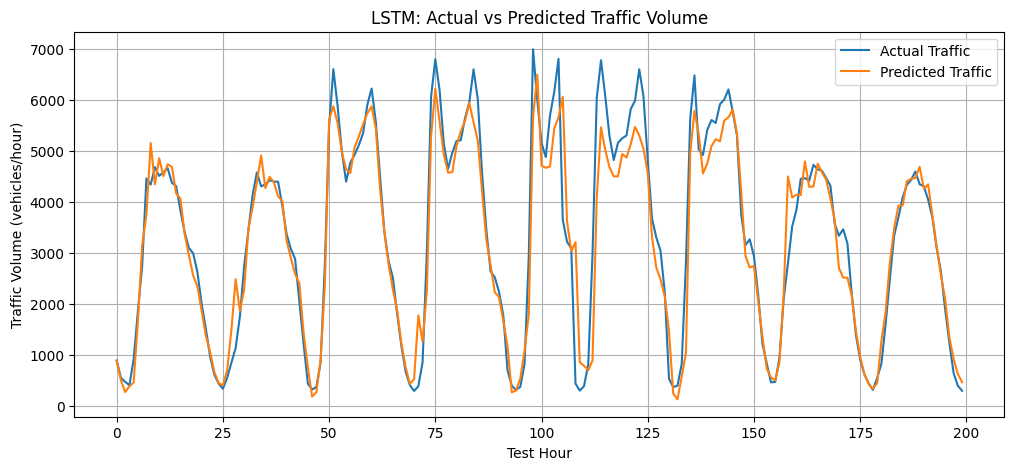

In [6]:

from sklearn.metrics import mean_absolute_error, mean_squared_error
import matplotlib.pyplot as plt
import numpy as np

# Predict unseen test data
pred_scaled = model.predict(X_test, verbose=0)

# Convert normalized values to original traffic volume
actual = y_test * (
    scaler.data_max_[target_idx] - scaler.data_min_[target_idx]
) + scaler.data_min_[target_idx]

predicted = pred_scaled.ravel() * (
    scaler.data_max_[target_idx] - scaler.data_min_[target_idx]
) + scaler.data_min_[target_idx]

# Calculate evaluation metrics
mae = mean_absolute_error(actual, predicted)
rmse = np.sqrt(mean_squared_error(actual, predicted))

print("Mean Absolute Error (MAE):", round(mae, 2))
print("Root Mean Squared Error (RMSE):", round(rmse, 2))

# Plot actual vs predicted traffic
plt.figure(figsize=(12, 5))
plt.plot(actual[:200], label="Actual Traffic")
plt.plot(predicted[:200], label="Predicted Traffic")
plt.title("LSTM: Actual vs Predicted Traffic Volume")
plt.xlabel("Test Hour")
plt.ylabel("Traffic Volume (vehicles/hour)")
plt.legend()
plt.grid(True)
plt.show()


In [7]:

# Use the latest 24 hours of data
last_24 = scaled[-24:].reshape(1, 24, scaled.shape[1])

# Predict next-hour traffic
next_scaled = model.predict(last_24, verbose=0)

# Convert normalized prediction to original vehicle count
next_traffic = (
    next_scaled[0, 0] *
    (scaler.data_max_[target_idx] - scaler.data_min_[target_idx])
    + scaler.data_min_[target_idx]
)

print("Predicted next-hour traffic volume:",
      round(float(next_traffic)), "vehicles/hour")


Predicted next-hour traffic volume: 5055 vehicles/hour
